In [1]:
# Cellule 1 — Installation des dépendances
!pip install numpy pandas matplotlib scipy scikit-learn torch tqdm seaborn

Defaulting to user installation because normal site-packages is not writeable


In [2]:
# Cellule 2 — Téléchargement et chargement du dataset NASA IMS
import os
import urllib.request
import zipfile
import pandas as pd
import numpy as np
from pathlib import Path

# ─── Téléchargement ──────────────────────────────────────────────────────────
DATA_DIR = './nasa_ims'
ZIP_URL  = 'https://phm-datasets.s3.amazonaws.com/NASA/4.+Bearings.zip'
ZIP_PATH = './nasa_bearings.zip'

if not os.path.exists(DATA_DIR):
    print("Téléchargement du dataset NASA IMS...")
    urllib.request.urlretrieve(ZIP_URL, ZIP_PATH)
    print("Extraction...")
    with zipfile.ZipFile(ZIP_PATH, 'r') as z:
        z.extractall(DATA_DIR)
    os.remove(ZIP_PATH)
    print("Dataset prêt !")
else:
    print("Dataset déjà présent ✅")

# ─── Exploration de la structure ─────────────────────────────────────────────
print("\nStructure du dataset :")
for item in sorted(Path(DATA_DIR).rglob('*'))[:20]:
    print(f"  {item}")

Téléchargement du dataset NASA IMS...
Extraction...
Dataset prêt !

Structure du dataset :
  nasa_ims\4. Bearings
  nasa_ims\4. Bearings\IMS.7z


Fichiers valides : 982


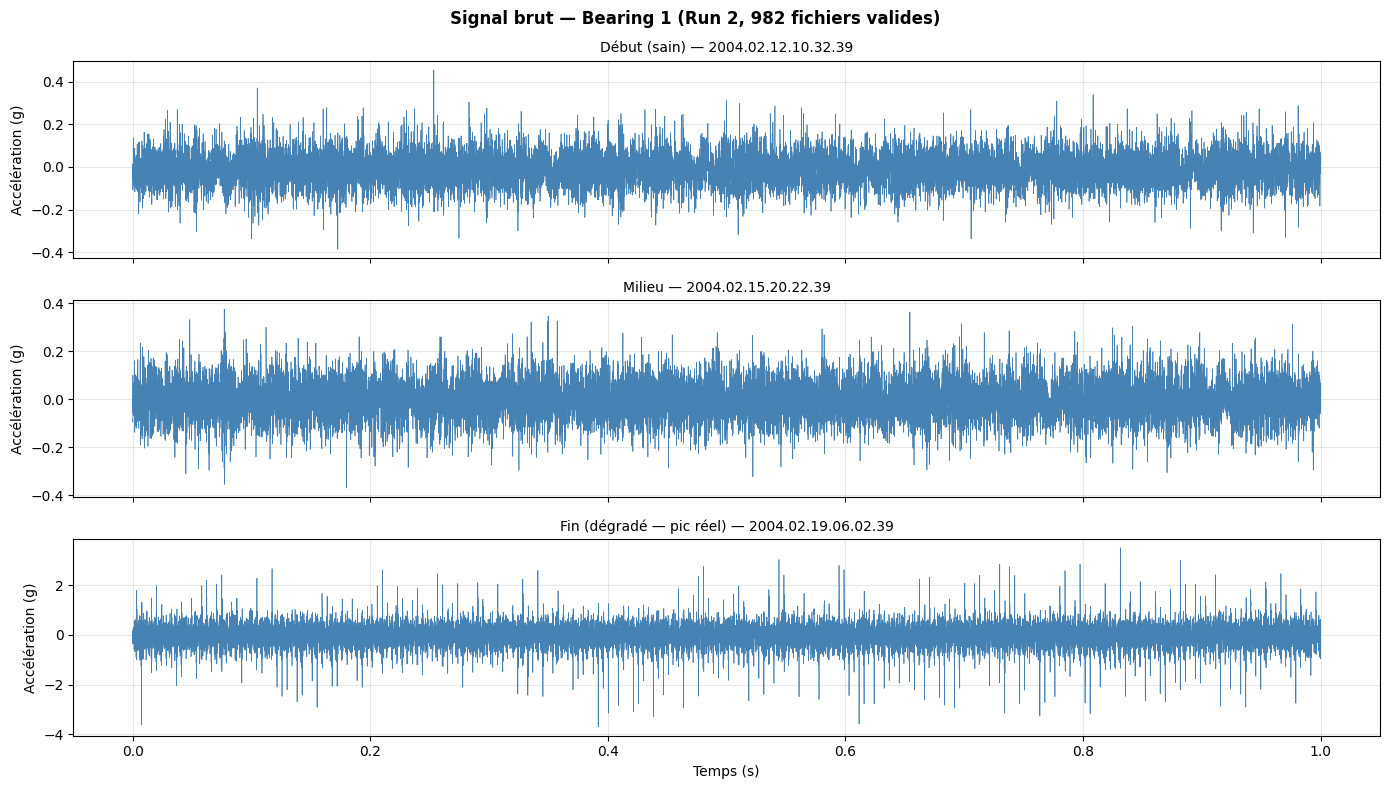

In [5]:
# Cellule 3 — corrigée
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from pathlib import Path

RUN2_DIR = Path('./nasa_ims/4. Bearings/IMS/2nd_test')
files = sorted(RUN2_DIR.glob('*'))[:-2]  # on exclut les 2 derniers artefacts
print(f"Fichiers valides : {len(files)}")

def load_file(path):
    return pd.read_csv(path, sep=r'\s+', header=None, names=['B1','B2','B3','B4'])

indices = [0, len(files)//2, len(files)-1]
labels  = ['Début (sain)', 'Milieu', 'Fin (dégradé — pic réel)']

fig, axes = plt.subplots(3, 1, figsize=(14, 8), sharex=True)
for ax, idx, label in zip(axes, indices, labels):
    df = load_file(files[idx])
    t  = np.linspace(0, 1, len(df))
    ax.plot(t, df['B1'].values, linewidth=0.5, color='steelblue')
    ax.set_title(f'{label} — {files[idx].name}', fontsize=10)
    ax.set_ylabel('Accélération (g)')
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel('Temps (s)')
plt.suptitle('Signal brut — Bearing 1 (Run 2, 982 fichiers valides)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('signal_brut_B1.png', dpi=150, bbox_inches='tight')
plt.show()

In [6]:
# Cellule 4 — Extraction features
import numpy as np
import pandas as pd
from scipy import stats
from pathlib import Path
from tqdm import tqdm

RUN2_DIR = Path('./nasa_ims/4. Bearings/IMS/2nd_test')
files = sorted(RUN2_DIR.glob('*'))[:-2]

def extract_features(signal):
    rms    = np.sqrt(np.mean(signal**2))
    peak   = np.max(np.abs(signal))
    fft_mag = np.abs(np.fft.rfft(signal))
    return {
        'rms'      : rms,
        'variance' : np.var(signal),
        'kurtosis' : stats.kurtosis(signal),
        'skewness' : stats.skew(signal),
        'peak'     : peak,
        'crest'    : peak / (rms + 1e-10),
        'fft_mean' : np.mean(fft_mag),
        'fft_std'  : np.std(fft_mag),
    }

rows = []
for f in tqdm(files, desc='Extraction'):
    df  = pd.read_csv(f, sep=r'\s+', header=None, names=['B1','B2','B3','B4'])
    row = extract_features(df['B1'].values)
    row['filename'] = f.name
    rows.append(row)

features_df = pd.DataFrame(rows)
features_df.to_csv('features_run2.csv', index=False)
print(f"\nShape : {features_df.shape}")
print(features_df.describe().round(4))

Extraction: 100%|██████████| 982/982 [00:56<00:00, 17.33it/s]


Shape : (982, 9)
            rms  variance  kurtosis  skewness      peak     crest  fft_mean  \
count  982.0000  982.0000  982.0000  982.0000  982.0000  982.0000  982.0000   
mean     0.1063    0.0147    0.8268   -0.0341    0.5561    5.1787    9.5711   
std      0.0581    0.0305    0.9594    0.0862    0.3877    0.5665    4.9287   
min      0.0740    0.0054   -0.2645   -0.7661    0.3150    3.4497    7.3468   
25%      0.0771    0.0059    0.3938   -0.0477    0.3930    4.8195    7.7219   
50%      0.0788    0.0062    0.4848   -0.0099    0.4420    5.0985    7.9098   
75%      0.1089    0.0119    0.8763    0.0136    0.5760    5.4411    9.9726   
max      0.7250    0.5256   14.1100    0.1206    5.0000    9.3333   77.5494   

        fft_std  
count  982.0000  
mean    11.7371  
std      6.8578  
min      7.3379  
25%      7.8929  
50%      8.0715  
75%     12.1546  
max     68.9209  


Sains    : 500 fichiers
Dégradés : 482 fichiers


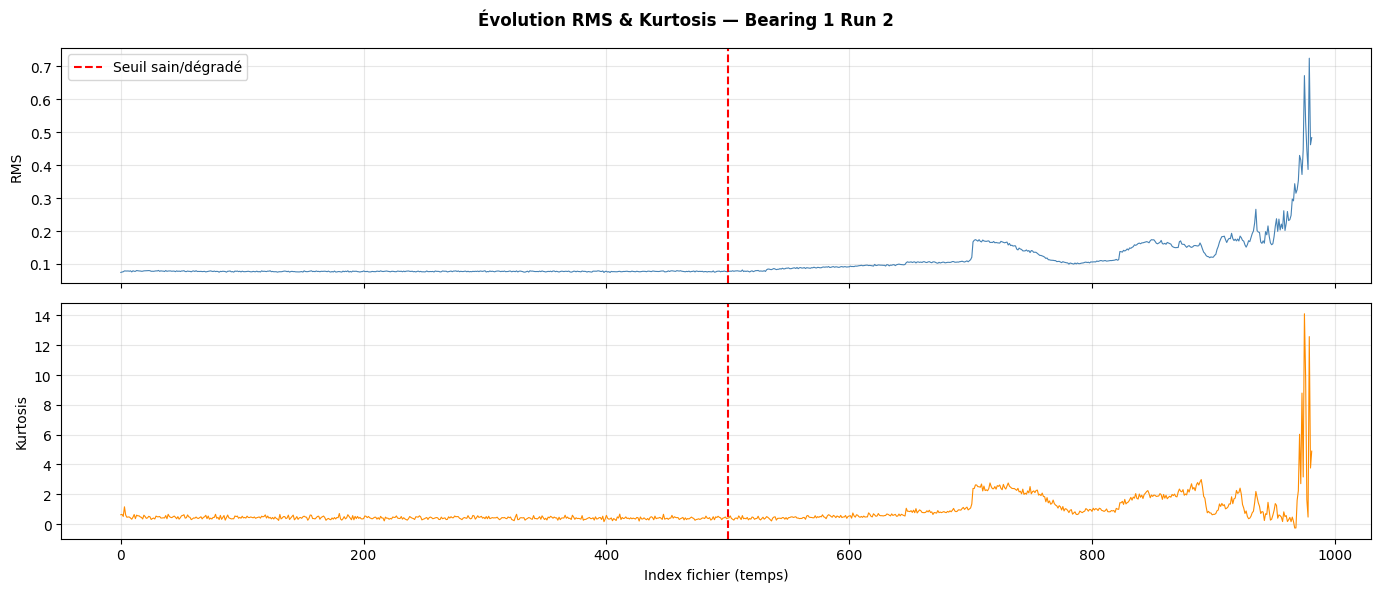


RMS moyen sains    : 0.0772
RMS moyen dégradés : 0.1365
Kurtosis moyen sains    : 0.4197
Kurtosis moyen dégradés : 1.2490


In [7]:
# Cellule 5 — Séparation sain / dégradé
import pandas as pd
import matplotlib.pyplot as plt

features_df = pd.read_csv('features_run2.csv')

SPLIT = 500  # premiers 500 = sains, reste = dégradés

healthy   = features_df.iloc[:SPLIT].copy()
degraded  = features_df.iloc[SPLIT:].copy()

print(f"Sains    : {len(healthy)} fichiers")
print(f"Dégradés : {len(degraded)} fichiers")

# ─── Visualisation RMS + Kurtosis sur toute la durée ─────────────────────────
fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)

x = range(len(features_df))

axes[0].plot(x, features_df['rms'], color='steelblue', linewidth=0.8)
axes[0].axvline(SPLIT, color='red', linestyle='--', label='Seuil sain/dégradé')
axes[0].set_ylabel('RMS')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(x, features_df['kurtosis'], color='darkorange', linewidth=0.8)
axes[1].axvline(SPLIT, color='red', linestyle='--')
axes[1].set_ylabel('Kurtosis')
axes[1].set_xlabel('Index fichier (temps)')
axes[1].grid(True, alpha=0.3)

plt.suptitle('Évolution RMS & Kurtosis — Bearing 1 Run 2', fontweight='bold')
plt.tight_layout()
plt.savefig('features_evolution.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"\nRMS moyen sains    : {healthy['rms'].mean():.4f}")
print(f"RMS moyen dégradés : {degraded['rms'].mean():.4f}")
print(f"Kurtosis moyen sains    : {healthy['kurtosis'].mean():.4f}")
print(f"Kurtosis moyen dégradés : {degraded['kurtosis'].mean():.4f}")

In [8]:
# Cellule 6 — Normalisation
from sklearn.preprocessing import StandardScaler
import numpy as np
import pandas as pd

features_df = pd.read_csv('features_run2.csv')

SPLIT = 500
feature_cols = ['rms', 'variance', 'kurtosis', 'skewness', 'peak', 'crest', 'fft_mean', 'fft_std']

healthy  = features_df.iloc[:SPLIT][feature_cols].values
degraded = features_df.iloc[SPLIT:][feature_cols].values

# Scaler fitté UNIQUEMENT sur les données saines
scaler = healthy_scaled = None
scaler = StandardScaler()
scaler.fit(healthy)

healthy_scaled  = scaler.transform(healthy)
degraded_scaled = scaler.transform(degraded)
all_scaled      = scaler.transform(features_df[feature_cols].values)

print(f"healthy_scaled  : {healthy_scaled.shape}")
print(f"degraded_scaled : {degraded_scaled.shape}")
print(f"all_scaled      : {all_scaled.shape}")
print(f"\nMoyenne sains (doit être ≈0) : {healthy_scaled.mean(axis=0).round(3)}")
print(f"Std sains (doit être ≈1)     : {healthy_scaled.std(axis=0).round(3)}")

# Sauvegarder pour la suite
import pickle
with open('scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)
np.save('healthy_scaled.npy',  healthy_scaled)
np.save('degraded_scaled.npy', degraded_scaled)
np.save('all_scaled.npy',      all_scaled)
print("\nScaler et données sauvegardés ✅")

healthy_scaled  : (500, 8)
degraded_scaled : (482, 8)
all_scaled      : (982, 8)

Moyenne sains (doit être ≈0) : [ 0.  0. -0. -0.  0. -0. -0.  0.]
Std sains (doit être ≈1)     : [1. 1. 1. 1. 1. 1. 1. 1.]

Scaler et données sauvegardés ✅


In [9]:
# Cellule 7 — Architecture Autoencoder 1D (PyTorch)
import torch
import torch.nn as nn

N_FEATURES = 8
LATENT_DIM = 16

class Autoencoder(nn.Module):
    def __init__(self, n_features, latent_dim):
        super().__init__()
        
        self.encoder = nn.Sequential(
            nn.Linear(n_features, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, latent_dim)
        )
        
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 32),
            nn.ReLU(),
            nn.Linear(32, 64),
            nn.ReLU(),
            nn.Linear(64, n_features)
        )
    
    def forward(self, x):
        z    = self.encoder(x)
        x_hat = self.decoder(z)
        return x_hat

# ─── Instanciation + vérification ────────────────────────────────────────────
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model  = Autoencoder(N_FEATURES, LATENT_DIM).to(device)

print(f"Device : {device}")
print(f"\n{model}")

# Test forward pass
x_test = torch.randn(32, N_FEATURES).to(device)
x_hat  = model(x_test)
print(f"\nInput  : {x_test.shape}")
print(f"Output : {x_hat.shape}")

total_params = sum(p.numel() for p in model.parameters())
print(f"\nParamètres totaux : {total_params}")

Device : cpu

Autoencoder(
  (encoder): Sequential(
    (0): Linear(in_features=8, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=16, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=16, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=8, bias=True)
  )
)

Input  : torch.Size([32, 8])
Output : torch.Size([32, 8])

Paramètres totaux : 6360


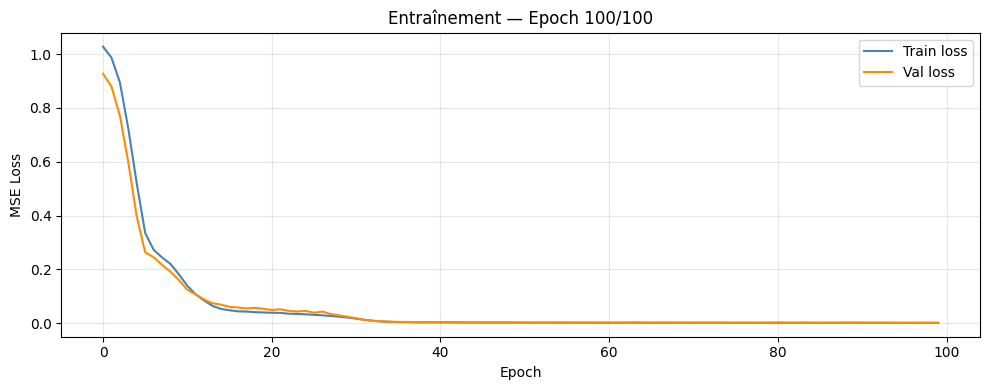

Entraînement: 100%|██████████| 100/100 [00:31<00:00,  3.13it/s]

Modèle sauvegardé ✅ | Meilleure val_loss=0.001374


In [10]:
# Cellule 8 — Entraînement + Early Stopping + courbe temps réel
import torch
import torch.nn as nn
import numpy as np
from torch.utils.data import DataLoader, TensorDataset
from tqdm import tqdm
from IPython.display import clear_output
import matplotlib.pyplot as plt

EPOCHS      = 100
BATCH_SIZE  = 32
LR          = 1e-3
TRAIN_RATIO = 0.7
PATIENCE    = 10   # early stop si val_loss n'améliore pas pendant 10 epochs

healthy_scaled = np.load('healthy_scaled.npy').astype(np.float32)
n_train = int(len(healthy_scaled) * TRAIN_RATIO)
X_train = torch.tensor(healthy_scaled[:n_train])
X_val   = torch.tensor(healthy_scaled[n_train:])

train_loader = DataLoader(TensorDataset(X_train), batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(TensorDataset(X_val),   batch_size=BATCH_SIZE, shuffle=False)

device    = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model     = Autoencoder(N_FEATURES, LATENT_DIM).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
criterion = nn.MSELoss()

train_losses, val_losses = [], []

# ─── Early stopping ──────────────────────────────────────────────────────────
best_val_loss  = np.inf
best_weights   = None
patience_count = 0

def plot_live(train_losses, val_losses, stopped=False):
    clear_output(wait=True)
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(train_losses, label='Train loss', color='steelblue')
    ax.plot(val_losses,   label='Val loss',   color='darkorange')
    title = f'Entraînement — Epoch {len(train_losses)}/{EPOCHS}'
    if stopped:
        title += f'  ⛔ Early stop (patience={PATIENCE})'
    ax.set_title(title)
    ax.set_xlabel('Epoch')
    ax.set_ylabel('MSE Loss')
    ax.legend()
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

for epoch in tqdm(range(EPOCHS), desc='Entraînement'):
    # Train
    model.train()
    batch_losses = []
    for (xb,) in train_loader:
        xb   = xb.to(device)
        loss = criterion(model(xb), xb)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        batch_losses.append(loss.item())

    # Validation
    model.eval()
    with torch.no_grad():
        val_loss = np.mean([
            criterion(model(xb.to(device)), xb.to(device)).item()
            for (xb,) in val_loader
        ])

    train_losses.append(np.mean(batch_losses))
    val_losses.append(val_loss)

    # ─── Logique early stopping ───────────────────────────────────────────────
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_weights  = model.state_dict().copy()
        patience_count = 0
    else:
        patience_count += 1

    plot_live(train_losses, val_losses)

    if patience_count >= PATIENCE:
        plot_live(train_losses, val_losses, stopped=True)
        print(f"\n⛔ Early stopping à l'epoch {epoch+1} | Meilleure val_loss={best_val_loss:.6f}")
        break

# Restaurer les meilleurs poids
model.load_state_dict(best_weights)
torch.save(model.state_dict(), 'autoencoder.pth')
print(f"Modèle sauvegardé ✅ | Meilleure val_loss={best_val_loss:.6f}")

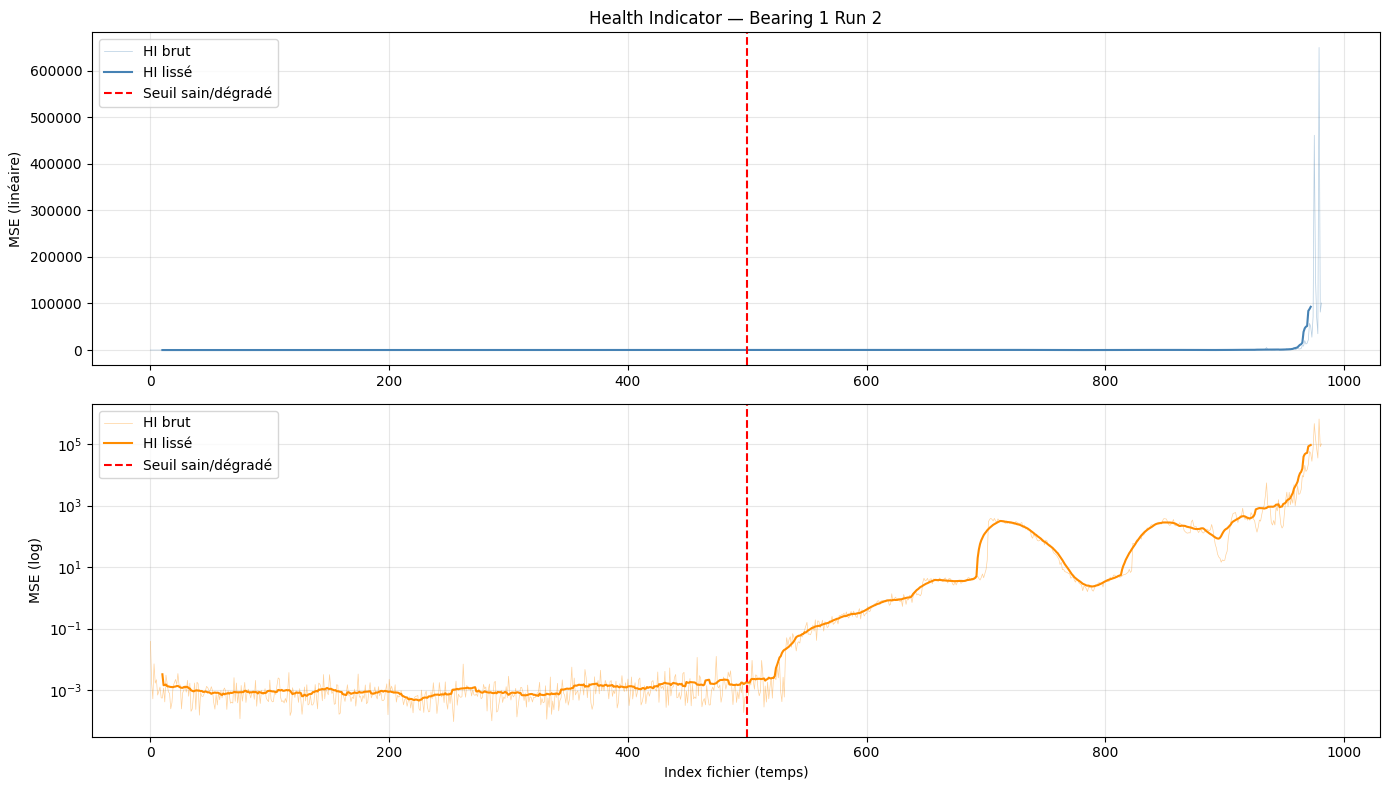

HI moyen sains    : 0.0011
HI moyen dégradés : 4017.3329
Ratio dégradé/sain : 3525484.3x


In [13]:
# Cellule 9b — Health Indicator amélioré (log + lissage)
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

hi_scores = np.load('hi_scores.npy')
SPLIT = 500

# Lissage (moyenne glissante sur 20 points)
window = 20
hi_smooth = pd.Series(hi_scores).rolling(window, center=True).mean().values

fig, axes = plt.subplots(2, 1, figsize=(14, 8))

# ─── Échelle linéaire + lissage ──────────────────────────────────────────────
axes[0].plot(hi_scores,  color='steelblue', linewidth=0.5, alpha=0.4, label='HI brut')
axes[0].plot(hi_smooth,  color='steelblue', linewidth=1.5, label='HI lissé')
axes[0].axvline(SPLIT, color='red', linestyle='--', label='Seuil sain/dégradé')
axes[0].set_ylabel('MSE (linéaire)')
axes[0].set_title('Health Indicator — Bearing 1 Run 2')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# ─── Échelle log (révèle la dégradation progressive) ─────────────────────────
axes[1].semilogy(hi_scores, color='darkorange', linewidth=0.5, alpha=0.4, label='HI brut')
axes[1].semilogy(hi_smooth, color='darkorange', linewidth=1.5, label='HI lissé')
axes[1].axvline(SPLIT, color='red', linestyle='--', label='Seuil sain/dégradé')
axes[1].set_ylabel('MSE (log)')
axes[1].set_xlabel('Index fichier (temps)')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('hi_ameliore.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"HI moyen sains    : {hi_scores[:SPLIT].mean():.4f}")
print(f"HI moyen dégradés : {hi_scores[SPLIT:].mean():.4f}")
print(f"Ratio dégradé/sain : {hi_scores[SPLIT:].mean() / hi_scores[:SPLIT].mean():.1f}x")

Seuil d'alerte (percentile 99) : 0.005608
Première alerte   : index 0
Fichiers restants : 982 (9820 minutes avant panne)


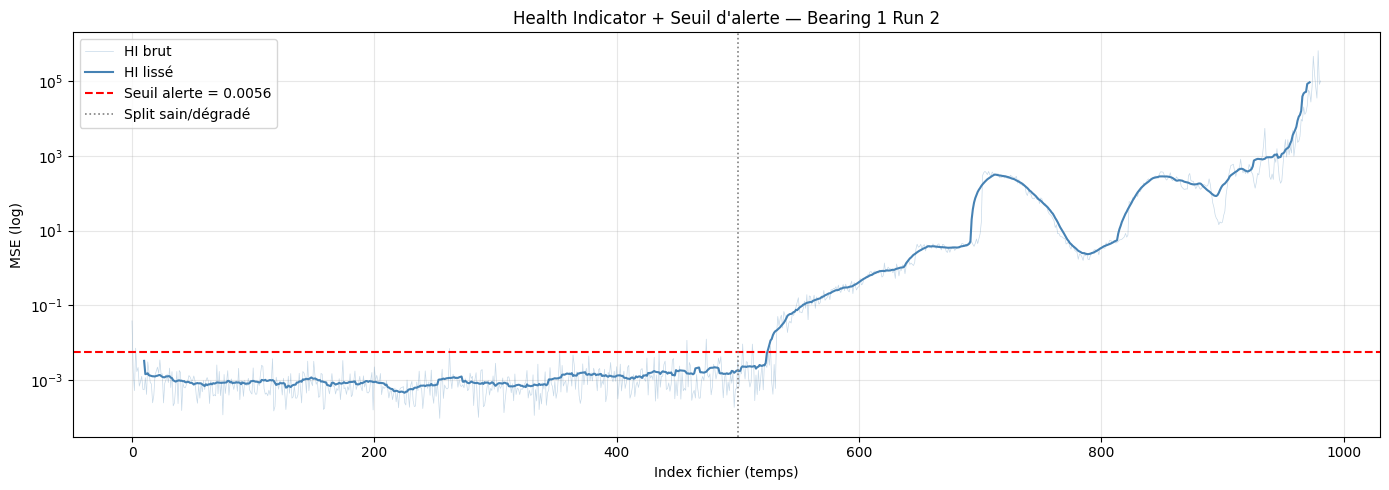

In [14]:
# Cellule 10 — Seuil d'alerte (percentile 99 sur données saines)
import numpy as np
import matplotlib.pyplot as plt

hi_scores = np.load('hi_scores.npy')
SPLIT     = 500

hi_sains = hi_scores[:SPLIT]
SEUIL    = np.percentile(hi_sains, 99)
print(f"Seuil d'alerte (percentile 99) : {SEUIL:.6f}")

# Index où le HI dépasse le seuil pour la première fois
alertes = np.where(hi_scores > SEUIL)[0]
first_alert = alertes[0] if len(alertes) > 0 else None
print(f"Première alerte   : index {first_alert}")
print(f"Fichiers restants : {len(hi_scores) - first_alert} ({(len(hi_scores) - first_alert) * 10} minutes avant panne)")

# ─── Visualisation ────────────────────────────────────────────────────────────
import pandas as pd
hi_smooth = pd.Series(hi_scores).rolling(20, center=True).mean().values

fig, ax = plt.subplots(figsize=(14, 5))
ax.semilogy(hi_scores,  color='steelblue', linewidth=0.5, alpha=0.3, label='HI brut')
ax.semilogy(hi_smooth,  color='steelblue', linewidth=1.5, label='HI lissé')
ax.axhline(SEUIL, color='red',    linestyle='--', linewidth=1.5, label=f'Seuil alerte = {SEUIL:.4f}')
ax.axvline(SPLIT, color='gray',   linestyle=':',  linewidth=1.2, label='Split sain/dégradé')
if first_alert:
    ax.axvline(first_alert, color='orange', linestyle='--', linewidth=1.5,
               label=f'1ère alerte @ index {first_alert}')
ax.set_xlabel('Index fichier (temps)')
ax.set_ylabel('MSE (log)')
ax.set_title('Health Indicator + Seuil d\'alerte — Bearing 1 Run 2')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('hi_seuil.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
# Cellule 10b — Stats seuil d'alerte
import numpy as np

hi_scores = np.load('hi_scores.npy')
SPLIT     = 500

hi_sains = hi_scores[:SPLIT]
SEUIL    = np.percentile(hi_sains, 99)
print(f"Seuil d'alerte (percentile 99) : {SEUIL:.6f}")

alertes     = np.where(hi_scores > SEUIL)[0]
first_alert = alertes[0] if len(alertes) > 0 else None

print(f"Première alerte   : index {first_alert}")
print(f"Fichiers restants : {len(hi_scores) - first_alert} ({(len(hi_scores) - first_alert) * 10} minutes avant panne)")
print(f"Soit environ      : {(len(hi_scores) - first_alert) * 10 / 60:.1f} heures avant panne")

Seuil d'alerte (percentile 99) : 0.005608
Première alerte   : index 0
Fichiers restants : 982 (9820 minutes avant panne)
Soit environ      : 163.7 heures avant panne


In [16]:
# Cellule 10c — Seuil corrigé
import numpy as np

hi_scores = np.load('hi_scores.npy')
SPLIT     = 500

hi_sains = hi_scores[10:SPLIT]          # on ignore le warm-up
SEUIL    = np.percentile(hi_sains, 99)
print(f"Seuil d'alerte corrigé : {SEUIL:.6f}")

alertes     = np.where(hi_scores[10:] > SEUIL)[0] + 10   # offset
first_alert = alertes[0] if len(alertes) > 0 else None

print(f"Première alerte   : index {first_alert}")
print(f"Fichiers restants : {len(hi_scores) - first_alert}")
print(f"Soit environ      : {(len(hi_scores) - first_alert) * 10 / 60:.1f} heures avant panne")

Seuil d'alerte corrigé : 0.004762
Première alerte   : index 262
Fichiers restants : 720
Soit environ      : 120.0 heures avant panne


In [17]:
# Cellule 10d — Seuil affiné
import numpy as np

hi_scores = np.load('hi_scores.npy')
SPLIT     = 500

hi_sains = hi_scores[10:SPLIT]

# Tester plusieurs percentiles
for p in [99, 99.5, 99.9, 99.99]:
    seuil = np.percentile(hi_sains, p)
    alertes = np.where(hi_scores[10:] > seuil)[0] + 10
    first   = alertes[0] if len(alertes) > 0 else None
    print(f"p={p:6.2f} | seuil={seuil:.6f} | 1ère alerte=index {first} | restants={len(hi_scores)-first if first else 'N/A'}")

p= 99.00 | seuil=0.004762 | 1ère alerte=index 262 | restants=720
p= 99.50 | seuil=0.006375 | 1ère alerte=index 262 | restants=720
p= 99.90 | seuil=0.012051 | 1ère alerte=index 474 | restants=508
p= 99.99 | seuil=0.012452 | 1ère alerte=index 474 | restants=508


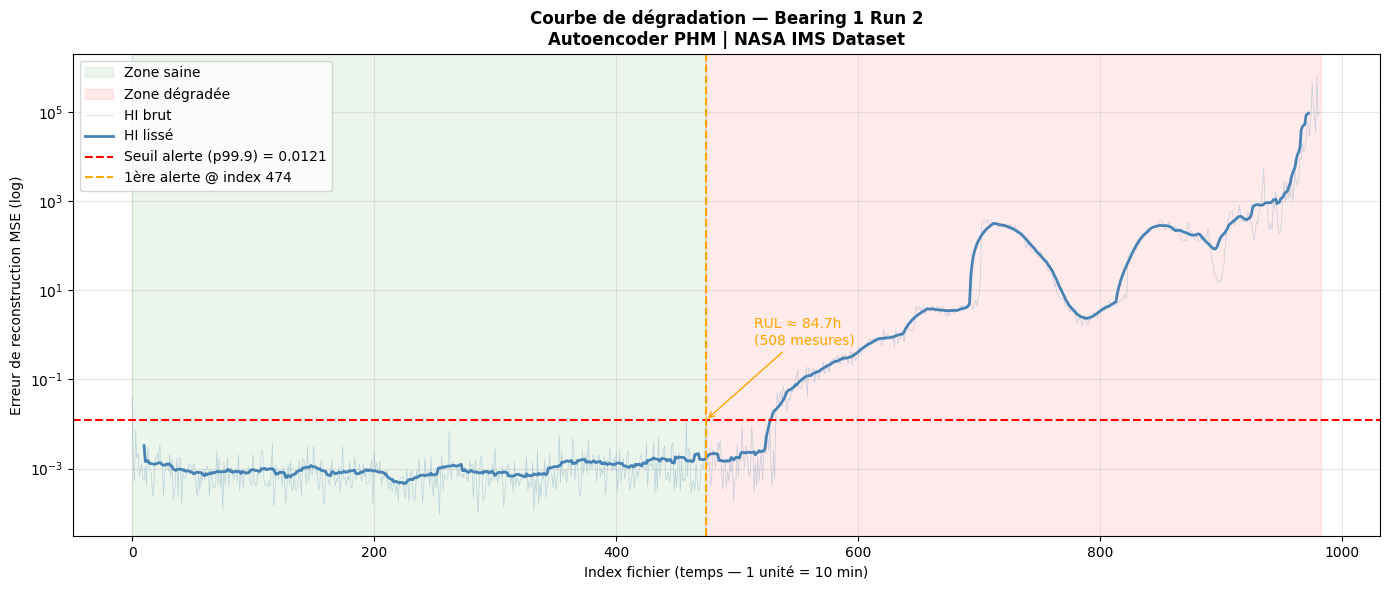

Seuil          : 0.012051
Première alerte: index 474
RUL estimé     : 84.7 heures


In [18]:
# Cellule 11 — Visualisation courbe dégradation finale
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

hi_scores = np.load('hi_scores.npy')
SPLIT     = 500
hi_sains  = hi_scores[10:SPLIT]
SEUIL     = np.percentile(hi_sains, 99.90)
FIRST_ALERT = 474

hi_smooth = pd.Series(hi_scores).rolling(20, center=True).mean().values

fig, ax = plt.subplots(figsize=(14, 6))

# Zones colorées
ax.axvspan(0,           FIRST_ALERT, alpha=0.08, color='green',  label='Zone saine')
ax.axvspan(FIRST_ALERT, len(hi_scores), alpha=0.08, color='red', label='Zone dégradée')

# Courbes
ax.semilogy(hi_scores, color='steelblue', linewidth=0.5, alpha=0.3, label='HI brut')
ax.semilogy(hi_smooth, color='steelblue', linewidth=2.0, label='HI lissé')

# Seuil + première alerte
ax.axhline(SEUIL, color='red', linestyle='--', linewidth=1.5,
           label=f'Seuil alerte (p99.9) = {SEUIL:.4f}')
ax.axvline(FIRST_ALERT, color='orange', linestyle='--', linewidth=1.5,
           label=f'1ère alerte @ index {FIRST_ALERT}')

# Annotation RUL
ax.annotate(f'RUL ≈ 84.7h\n({len(hi_scores)-FIRST_ALERT} mesures)',
            xy=(FIRST_ALERT, SEUIL),
            xytext=(FIRST_ALERT + 40, SEUIL * 50),
            fontsize=10, color='orange',
            arrowprops=dict(arrowstyle='->', color='orange'))

ax.set_xlabel('Index fichier (temps — 1 unité = 10 min)')
ax.set_ylabel('Erreur de reconstruction MSE (log)')
ax.set_title('Courbe de dégradation — Bearing 1 Run 2\nAutoencoder PHM | NASA IMS Dataset', fontweight='bold')
ax.legend(loc='upper left')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('degradation_finale.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"Seuil          : {SEUIL:.6f}")
print(f"Première alerte: index {FIRST_ALERT}")
print(f"RUL estimé     : {(len(hi_scores) - FIRST_ALERT) * 10 / 60:.1f} heures")

Simulation: 100%|██████████| 982/982 [00:57<00:00, 16.98it/s]
C:\Users\PC\AppData\Local\Temp\ipykernel_7328\3842658352.py:95: UserWarning: Glyph 128994 (\N{LARGE GREEN CIRCLE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\PC\AppData\Local\Temp\ipykernel_7328\3842658352.py:95: UserWarning: Glyph 128993 (\N{LARGE YELLOW CIRCLE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\PC\AppData\Local\Temp\ipykernel_7328\3842658352.py:95: UserWarning: Glyph 128308 (\N{LARGE RED CIRCLE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\PC\AppData\Local\Temp\ipykernel_7328\3842658352.py:96: UserWarning: Glyph 128994 (\N{LARGE GREEN CIRCLE}) missing from font(s) DejaVu Sans.
  plt.savefig('simulation_finale.png', dpi=150, bbox_inches='tight')
C:\Users\PC\AppData\Local\Temp\ipykernel_7328\3842658352.py:96: UserWarning: Glyph 128993 (\N{LARGE YELLOW CIRCLE}) missing from font(s) DejaVu Sans.
  plt.savefig('simulation_finale.png', dpi=150, bbox_inches='

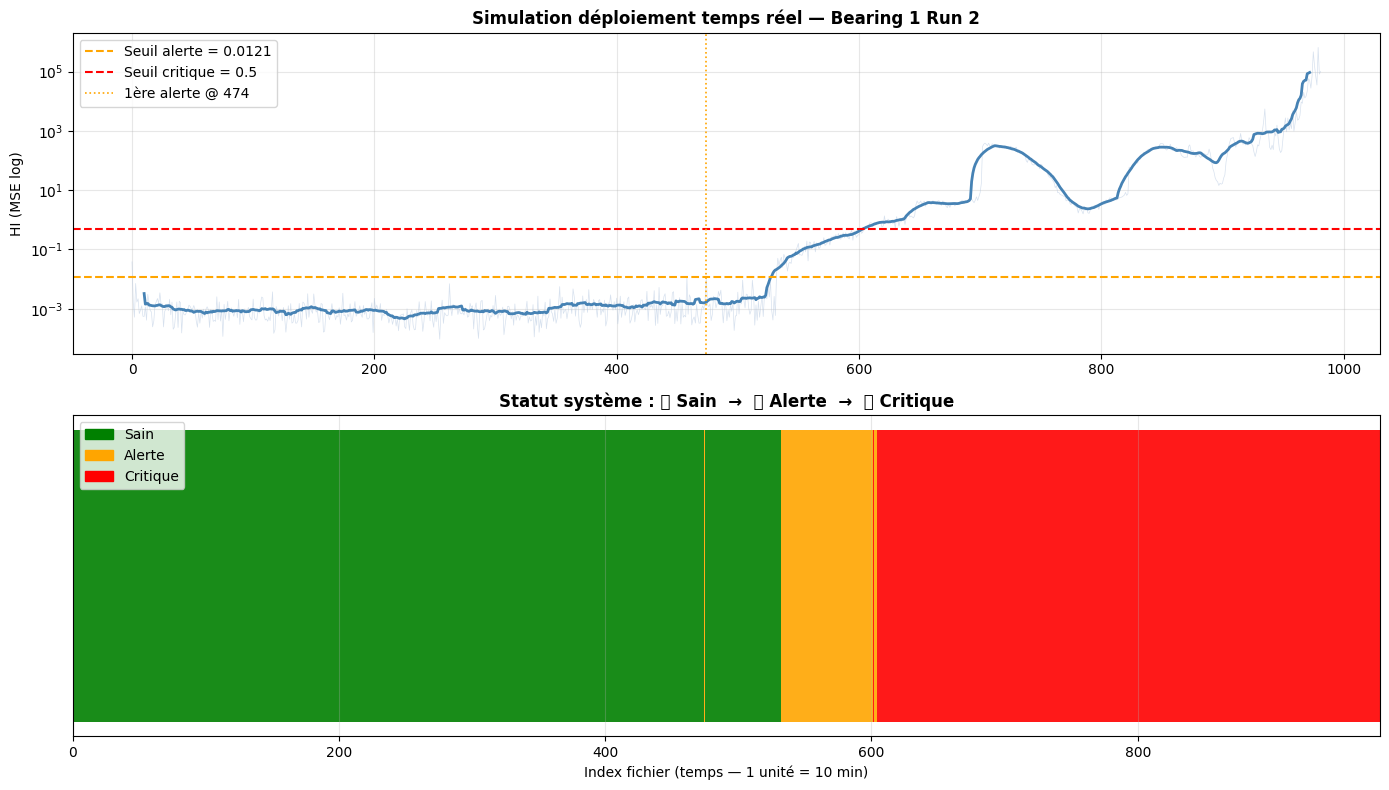

Simulation terminée ✅


In [35]:
# Cellule 12c — Simulation statique (compatible VS Code)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import torch
from scipy import stats
import pickle

RUN2_DIR = Path('./nasa_ims/4. Bearings/IMS/2nd_test')
files    = sorted(RUN2_DIR.glob('*'))[:-2]

with open('scaler.pkl', 'rb') as f:
    scaler = pickle.load(f)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model  = Autoencoder(N_FEATURES, LATENT_DIM).to(device)
model.load_state_dict(torch.load('autoencoder.pth', map_location=device))
model.eval()

SEUIL   = 0.012051
N_TOTAL = len(files)
STEP    = 1

def extract_features(signal):
    rms     = np.sqrt(np.mean(signal**2))
    peak    = np.max(np.abs(signal))
    fft_mag = np.abs(np.fft.rfft(signal))
    return np.array([rms, np.var(signal), stats.kurtosis(signal),
                     stats.skew(signal), peak, peak/(rms+1e-10),
                     np.mean(fft_mag), np.std(fft_mag)])

from tqdm import tqdm
hi_history, idx_history, status_history = [], [], []

SEUIL_CRITIQUE = 0.5   # HI > 0.5 → critique (empirique sur nos données)

for i, f in enumerate(tqdm(files[::STEP], desc='Simulation')):
    idx  = i * STEP
    df   = pd.read_csv(f, sep=r'\s+', header=None, names=['B1','B2','B3','B4'])
    feat = extract_features(df['B1'].values).reshape(1, -1)
    feat_sc = scaler.transform(feat).astype(np.float32)

    with torch.no_grad():
        x     = torch.tensor(feat_sc).to(device)
        x_hat = model(x)
        hi    = torch.nn.functional.mse_loss(x_hat, x).item()

    hi_history.append(hi)
    idx_history.append(idx)

    if hi < SEUIL:
        status_history.append(0)          # Sain
    elif hi < SEUIL_CRITIQUE:
        status_history.append(1)          # Alerte
    else:
        status_history.append(2)          # Critique

# ─── Figure finale ────────────────────────────────────────────────────────────
hi_arr    = np.array(hi_history)
hi_smooth = pd.Series(hi_arr).rolling(20, center=True).mean().values

fig, axes = plt.subplots(2, 1, figsize=(14, 8))

# Courbe HI
axes[0].semilogy(idx_history, hi_arr,    color='lightsteelblue', linewidth=0.5, alpha=0.5)
axes[0].semilogy(idx_history, hi_smooth, color='steelblue', linewidth=2)
axes[0].axhline(SEUIL,          color='orange', linestyle='--', linewidth=1.5,
                label=f'Seuil alerte = {SEUIL:.4f}')
axes[0].axhline(SEUIL_CRITIQUE, color='red',    linestyle='--', linewidth=1.5,
                label=f'Seuil critique = {SEUIL_CRITIQUE}')
axes[0].axvline(474, color='orange', linestyle=':', linewidth=1.2, label='1ère alerte @ 474')
axes[0].set_ylabel('HI (MSE log)')
axes[0].set_title('Simulation déploiement temps réel — Bearing 1 Run 2', fontweight='bold')
axes[0].legend(); axes[0].grid(True, alpha=0.3)

# Barre statut
for idx, s in zip(idx_history, status_history):
    c = ['green', 'orange', 'red'][s]
    axes[1].barh(0, 1, left=idx, color=c, height=0.4, alpha=0.9)

axes[1].set_xlim(0, N_TOTAL)
axes[1].set_yticks([])
axes[1].set_xlabel('Index fichier (temps — 1 unité = 10 min)')
axes[1].set_title('Statut système : 🟢 Sain  →  🟡 Alerte  →  🔴 Critique', fontweight='bold')

from matplotlib.patches import Patch
axes[1].legend(handles=[
    Patch(color='green',  label='Sain'),
    Patch(color='orange', label='Alerte'),
    Patch(color='red',    label='Critique'),
], loc='upper left')
axes[1].grid(True, alpha=0.3, axis='x')

plt.tight_layout()
plt.savefig('simulation_finale.png', dpi=150, bbox_inches='tight')
plt.show()
print("Simulation terminée ✅")